In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

path = "/home/madhav/workstation/Lab/DataSet/dataset_w1.2.csv"
df = pd.read_csv(path)

print(f"shape : {df.shape}")

df.head()

shape : (10000, 12)


,Date,Year,Locality,Estimated Value,Sale Price,Property,Residential,num_rooms,num_bathrooms,carpet_area,property_tax_rate,Face
0,2009-01-02,2009,Waterbury,111440.0,185000.0,Single Family,Detached House,3,3,996.0,1.025953,South
1,2009-01-02,2009,Bridgeport,124670.0,150000.0,Two Family,Duplex,4,3,1241.0,1.025953,South
2,2009-01-02,2009,Waterbury,55720.0,140000.0,Single Family,Detached House,3,2,910.0,1.025953,South
3,2009-01-02,2009,Bridgeport,4775276.0,272900.0,Single Family,Detached House,3,1,971.0,1.025953,East
4,2009-01-02,2009,Bridgeport,112351.0,210000.0,?,Detached House,3,2,1092.0,1.025953,East


In [41]:
# select through even indexing the row of the given table
import numpy as np

# Load up number for the even indexing through given number
even_indexing = np.arange(2, len(df), 2)

new_indexed = df.iloc[even_indexing].copy()

# making new location acces with iloc
new_indexed.iloc[332, 3]

np.float64(111861.0)

In [47]:
# even indexing rows and columns both
row, column = df.shape

row_index = np.arange(2, row, 2)
column_index = np.arange(2,column,2)

print(f"row indexing inspection : {row_index[0], row_index[-1]}")
print(f"column indexing inspection : {column_index[0], column_index[-1]}")

# New data frame with new slected special indexing
new_df = df.iloc[row_index, column_index].copy()
print(new_df.head())
new_df.iloc[254,2]

row indexing inspection : (np.int64(2), np.int64(9998))
column indexing inspection : (np.int64(2), np.int64(10))
      Locality  Sale Price     Residential  num_bathrooms  property_tax_rate
2    Waterbury    140000.0  Detached House              2           1.025953
4   Bridgeport    210000.0  Detached House              2           1.025953
6      Norwalk   1000000.0  Detached House              2           1.025953
8          NaN   1680000.0  Detached House              1           1.025953
10  Bridgeport    256500.0  Detached House              1           1.025953


'Detached House'

In [26]:
# Odd indexing the given data frame
odd_indexing = np.arange(1, len(df), 2)

odd_df = df.iloc[odd_indexing].copy()

odd_df.iloc[332,3]

np.float64(352940.0)

In [50]:
odd_df.iloc[100,5]

'Single Family'

In [58]:
# Inspecting date

count = 0
for date in df["Date"]:
    splits = date.split('-')
    year = int(splits[0]) # year extracted

    # Yearing logic for 6 most recent years
    if 2020 <= year:
        count += 1
        
print(count)

2442


In [66]:
# Chained conditioning into the dataset
condition = ((df["num_rooms"]==3)&(df['num_bathrooms']==3))

len(df[condition])

2730

In [68]:
condition = ((df["num_rooms"]==3)|(df['num_bathrooms']==3))

len(df[condition])

8591

In [78]:
# Building condition listing for the all given years
boolean_indexing = []

for date in df["Date"]:
    year = int(date.split('-')[0])
    if year == 2022:
        boolean_indexing.append(True)
    else:
        boolean_indexing.append(False)
new_indexing = pd.Series(boolean_indexing)

# condition for rooms
df_timed = df[new_indexing].copy()
cond1 = (df_timed['num_rooms'] == 3)

len(df_timed[cond1])

694

In [83]:
# Month of august accross all years
'''
Target second split value as month for comparision
target lock 8
'''
boolean_indexing = []

for date in df["Date"]:
    month = int(date.split('-')[1])
    if month == 8:
        boolean_indexing.append(True)
    else:
        boolean_indexing.append(False)

ind1 = pd.Series(boolean_indexing)

len(df[ind1])

1050

<BarContainer object of 7 artists>

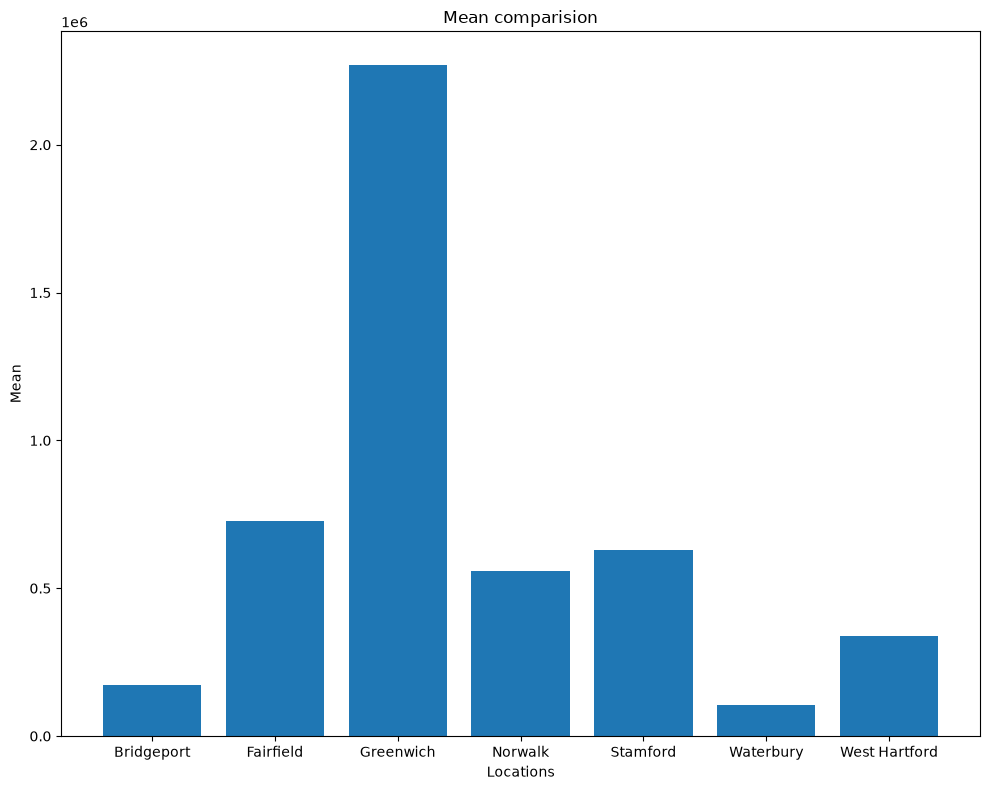

In [90]:
# Highest average sale prize inspection
import matplotlib.pyplot as plt

info = df.groupby('Locality')['Sale Price'].mean()

x = info.index
y = info

fig, ax = plt.subplots(figsize=(10,8), layout='tight')

ax.set(
    xlabel="Locations",
    ylabel="Mean",
    title="Mean comparision"
)

ax.bar(x,y)